In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [17]:
from sklearn.datasets import load_iris

# Tải tập dữ liệu Iris
iris = load_iris()

# Tạo DataFrame
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: iris.target_names[0],
                                  1: iris.target_names[1],
                                  2: iris.target_names[2]})
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [18]:
# Hiển thị 5 dòng đầu tiên
print(" --- 5 dong dau tien của du liệu --- ")
display(df.head())

 --- 5 dong dau tien của du liệu --- 


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [19]:
# Kiểm tra thông tin tập dữ liệu
print("\n --- Thông tin du liệu --- ")
df.info()


 --- Thông tin du liệu --- 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


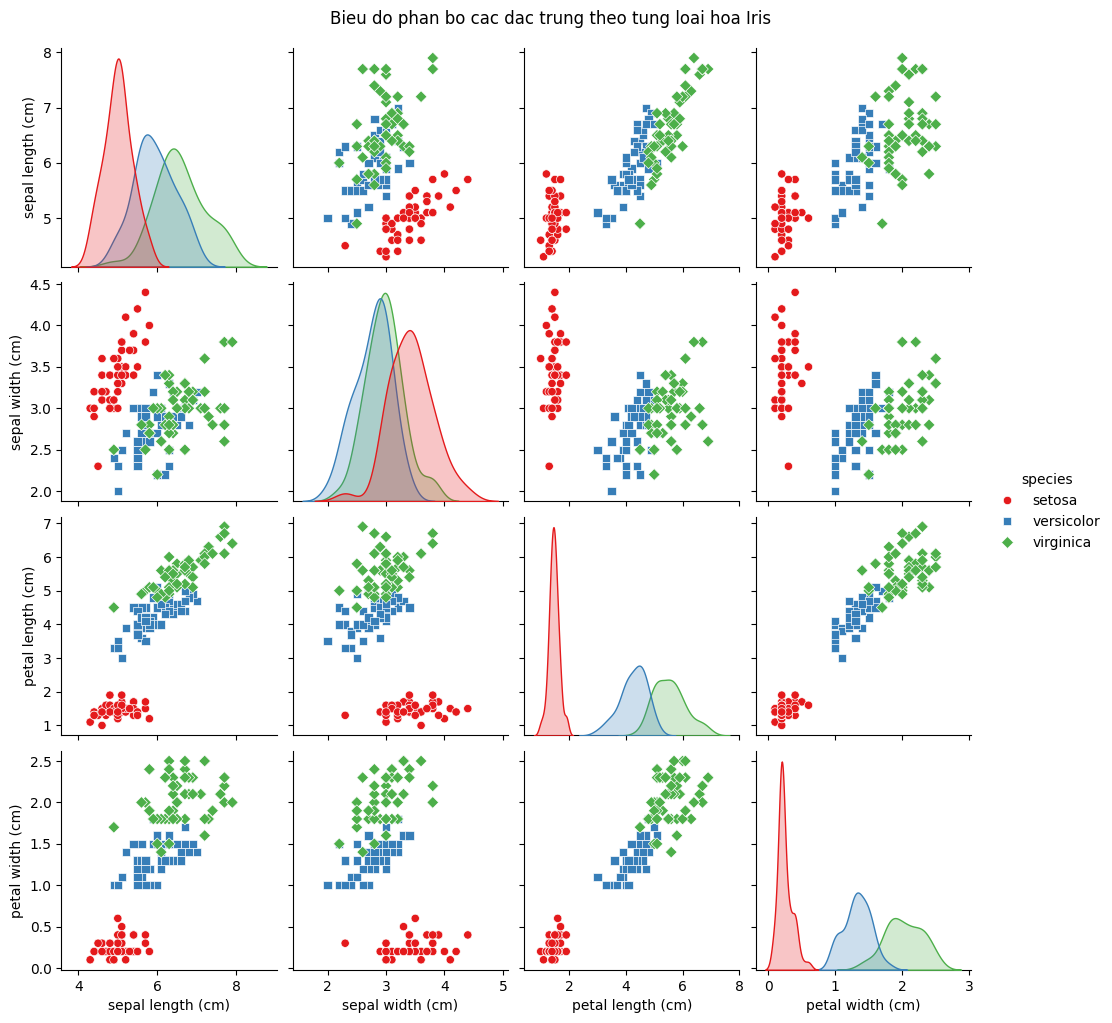

In [20]:
# Trực quan hoa phan bo cac loai hoa bang Pairplot
sns.pairplot(df.drop('target', axis=1), hue='species', palette='Set1', markers=["o", "s", "D"])
plt.suptitle("Bieu do phan bo cac dac trung theo tung loai hoa Iris", y=1.02)
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

# Khai báo X (đặc trưng) và y (nhãn)
X = iris.data
y = iris.target

# Chia dữ liệu theo tỉ lệ 80% Train - 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Kích thước tập Train (X_train): {X_train.shape}")
print(f"Kích thước tập Test (X_test): {X_test.shape}")

Kích thước tập Train (X_train): (120, 4)
Kích thước tập Test (X_test): (30, 4)


In [22]:
from sklearn.naive_bayes import GaussianNB

# Khởi tạo mô hình Gaussian Naive Bayes
model = GaussianNB()

# Huấn luyện mô hình
model.fit(X_train, y_train)

print("Đã huấn luyện xong mô hình Gaussian Naive Bayer")

Đã huấn luyện xong mô hình Gaussian Naive Bayer


In [23]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Dự đoán nhãn trên tập Test
y_pred = model.predict(X_test)

# Tính độ chính xác (Accuracy)
acc = accuracy_score(y_test, y_pred)
print(f"Độ chính xác (Accuracy) trên tập Test: {acc * 100:.2f}%\n")

Độ chính xác (Accuracy) trên tập Test: 96.67%



In [24]:
# In report (Precision, Recall, F1-Score)
print("--- Báo cáo chi tiết (Classification Report) ---")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

--- Báo cáo chi tiết (Classification Report) ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



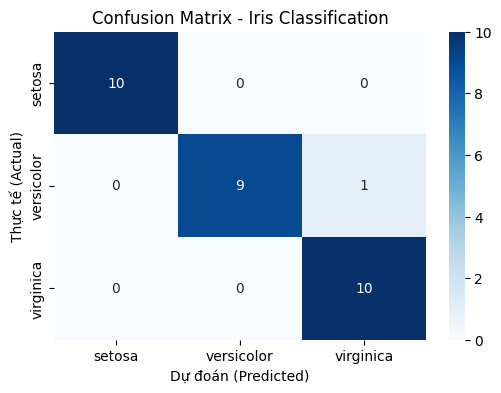

In [25]:
# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.title('Confusion Matrix - Iris Classification')
plt.show()

In [26]:
# Mẫu hoa mới: [sepal length, sepal width, petal length, petal width]
# Ví dụ: 5.1 cm, 3.5 cm, 1.4 cm, 0.2 cm
sample = np.array([[5.1, 3.5, 1.4, 0.2]])

# Dự đoán lớp
pred_class = model.predict(sample)[0]
pred_species = iris.target_names[pred_class]

# Tính xác suất cụ thể cho từng lớp bằng predict_proba
probabilities = model.predict_proba(sample)[0]

print(f" Mẫu hoa nhập vào thuộc loài: >>> {pred_species.upper()} <<<")
print("\nXác suất tương ứng với từng loài:")
for i, species_name in enumerate(iris.target_names):
    print(f" - {species_name}: {probabilities[i] * 100:.2f}%")

 Mẫu hoa nhập vào thuộc loài: >>> SETOSA <<<

Xác suất tương ứng với từng loài:
 - setosa: 100.00%
 - versicolor: 0.00%
 - virginica: 0.00%


---
# PHẦN 2: XÂY DỰNG WEB DEMO BẰNG STREAMLIT
Viết lại demo Gradio ở bối cảnh bài lab bằng **Streamlit**, giữ nguyên chức năng và bố cục 2 cột (không dùng Gradio).

Quy trình: (1) cài Streamlit → (2) chuẩn bị ảnh minh họa → (3) ghi file `app.py` → (4) chạy ứng dụng trên Colab → (5) kiểm thử 4 trường hợp.

### Bước 1. Cài đặt Streamlit

In [ ]:
!pip install -q streamlit

### Bước 2. Chuẩn bị ảnh minh họa
Gom 3 ảnh từ Google Drive vào thư mục `images/` (cạnh `app.py`) với tên `setosa.jpg`, `versicolor.jpg`, `virginica.jpg` để dùng đường dẫn tương đối trong app.

In [ ]:
import os, shutil
from google.colab import drive

# Kết nối Google Drive (nơi lưu ảnh)
drive.mount('/content/drive')

# Đường dẫn ảnh gốc trên Drive cho từng loài
DRIVE_FILES = {
    "setosa": "/content/drive/MyDrive/1790997729001_1727970218485350202_g5218412290016129451_e3084215504a0fedd6d558ea6c050578.jpg",
    "versicolor": "/content/drive/MyDrive/1790997729290_1727970218485350202_g5218412290016129451_c7e6b309ff702208f70fd86757b5f52c.jpg",
    "virginica": "/content/drive/MyDrive/1790997729742_1727970218485350202_g5218412290016129451_ed6311813705d3b92fff61f0683d18c0.jpg",
}

# Tạo thư mục images/ và sao chép ảnh vào (đổi tên theo loài)
os.makedirs("images", exist_ok=True)
for species, path in DRIVE_FILES.items():
    if os.path.exists(path):
        shutil.copy(path, f"images/{species}.jpg")
        print(f"Đã chép ảnh {species}")
    else:
        print(f"Không tìm thấy ảnh {species} tại: {path}")

### Bước 3. Ghi file `app.py`
Cấu trúc code tách thành các phần: cấu hình trang → hàm huấn luyện có cache (`@st.cache_resource`) → hàm dự đoán → hàm hiển thị → giao diện chính.

In [ ]:
%%writefile app.py
# =====================================================================
# DEMO PHÂN LOẠI HOA IRIS BẰNG STREAMLIT (Gaussian Naive Bayes)
# Chạy: streamlit run app.py
# =====================================================================
import os

import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# ---------------------------------------------------------------------
# 1. CẤU HÌNH TRANG
# ---------------------------------------------------------------------
st.set_page_config(page_title="Iris Classification - Naive Bayes", layout="wide")

# Thư mục chứa ảnh minh họa (đặt cạnh file app.py)
IMAGE_DIR = "images"
SPECIES_IMAGES = {
    "setosa": os.path.join(IMAGE_DIR, "setosa.jpg"),
    "versicolor": os.path.join(IMAGE_DIR, "versicolor.jpg"),
    "virginica": os.path.join(IMAGE_DIR, "virginica.jpg"),
}


# ---------------------------------------------------------------------
# 2. HÀM HUẤN LUYỆN MÔ HÌNH (có cache -> chỉ chạy 1 lần)
# ---------------------------------------------------------------------
@st.cache_resource
def load_model():
    """Huấn luyện GaussianNB trên toàn bộ dữ liệu Iris (giống bản Gradio).
    Đồng thời tính độ chính xác trên tập Test (80/20) để hiển thị ở sidebar."""
    iris = load_iris()
    X, y = iris.data, iris.target

    # Mô hình dùng để demo: huấn luyện trên toàn bộ dữ liệu
    model = GaussianNB()
    model.fit(X, y)

    # Mô hình tham chiếu để đo độ chính xác trên tập Test
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    eval_model = GaussianNB().fit(X_train, y_train)
    acc = accuracy_score(y_test, eval_model.predict(X_test))
    return model, iris, acc


@st.cache_data
def load_dataframe():
    """Tạo DataFrame Iris để hiển thị bảng và vẽ biểu đồ."""
    iris = load_iris()
    df = pd.DataFrame(iris.data, columns=iris.feature_names)
    df["species"] = [iris.target_names[t] for t in iris.target]
    return df


# ---------------------------------------------------------------------
# 3. HÀM DỰ ĐOÁN
# ---------------------------------------------------------------------
def predict_iris(model, iris, sl, sw, pl, pw):
    """Trả về (tên loài dự đoán, mảng xác suất 3 loài)."""
    sample = np.array([[sl, sw, pl, pw]])
    pred = model.predict(sample)[0]
    probs = model.predict_proba(sample)[0]
    return iris.target_names[pred], probs


# ---------------------------------------------------------------------
# 4. CÁC HÀM HIỂN THỊ
# ---------------------------------------------------------------------
def show_species_image(species):
    """Hiển thị ảnh minh họa; nếu thiếu file thì cảnh báo, không làm dừng app."""
    path = SPECIES_IMAGES.get(species)
    if path is not None and os.path.exists(path):
        st.image(path, caption=f"Hình minh họa loài {species.capitalize()}", width=320)
    else:
        st.warning(f"Không tìm thấy file ảnh minh họa cho loài '{species}' ({path}).")


def show_probabilities(iris, probs):
    """Hiển thị xác suất của cả 3 loài bằng thanh tiến trình."""
    st.markdown("#### Xác suất tương ứng từng loài")
    for name, p in zip(iris.target_names, probs):
        st.write(f"**{name.capitalize()}**: {p * 100:.2f}%")
        st.progress(float(p))


def plot_scatter(df, user_point):
    """Scatter plot phân bố dữ liệu và đánh dấu điểm người dùng vừa nhập."""
    sl, sw, pl, pw = user_point
    colors = {"setosa": "tab:red", "versicolor": "tab:blue", "virginica": "tab:green"}
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    pairs = [
        ("sepal length (cm)", "sepal width (cm)", sl, sw),
        ("petal length (cm)", "petal width (cm)", pl, pw),
    ]
    for ax, (xc, yc, ux, uy) in zip(axes, pairs):
        for sp, g in df.groupby("species"):
            ax.scatter(g[xc], g[yc], c=colors[sp], label=sp, alpha=0.6, s=25)
        ax.scatter(ux, uy, c="gold", edgecolors="black", marker="*", s=300,
                   label="Điểm bạn nhập", zorder=5)
        ax.set_xlabel(xc)
        ax.set_ylabel(yc)
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    st.pyplot(fig)


# ---------------------------------------------------------------------
# 5. GIAO DIỆN CHÍNH
# ---------------------------------------------------------------------
model, iris, test_acc = load_model()
df = load_dataframe()

# --- Sidebar: thông tin mô hình (bonus)
with st.sidebar:
    st.header("Thông tin mô hình")
    st.write("**Thuật toán:** Gaussian Naive Bayes")
    st.write("**Dữ liệu:** Iris (150 mẫu, 4 đặc trưng, 3 lớp)")
    st.write("**Chia dữ liệu:** 80% Train / 20% Test")
    st.metric("Độ chính xác trên tập Test", f"{test_acc * 100:.2f}%")
    st.caption("random_state=42, stratify=y. Mô hình demo được huấn luyện trên toàn bộ dữ liệu.")

# --- Tiêu đề
st.title("Demo Phân Loại Hoa Iris Dataset")
st.markdown("### Mô hình: **Gaussian Naive Bayes**")
st.markdown(
    "Nhập thông tin kích thước ở cột bên trái, bấm **Dự đoán ngay** "
    "để xem loài hoa tương ứng ở cột bên phải."
)

# --- Bố cục 2 cột
col_left, col_right = st.columns(2)

with col_left:
    st.subheader("Nhập thông tin mẫu hoa")
    sl = st.slider("Chiều dài lá đài (Sepal Length - cm)", 4.0, 8.0, 5.1, 0.1)
    sw = st.slider("Chiều rộng lá đài (Sepal Width - cm)", 2.0, 4.5, 3.5, 0.1)
    pl = st.slider("Chiều dài cánh hoa (Petal Length - cm)", 1.0, 7.0, 1.4, 0.1)
    pw = st.slider("Chiều rộng cánh hoa (Petal Width - cm)", 0.1, 2.5, 0.2, 0.1)
    clicked = st.button("Dự đoán ngay", type="primary")

with col_right:
    st.subheader("Kết quả dự đoán")
    if clicked:
        species, probs = predict_iris(model, iris, sl, sw, pl, pw)
        st.markdown(f"### Loài hoa được dự đoán: **{species.upper()}**")
        show_species_image(species)
        show_probabilities(iris, probs)
    else:
        st.info("Chưa có kết quả. Hãy chỉnh thanh trượt rồi bấm 'Dự đoán ngay'.")

# --- Biểu đồ phân bố (chỉ hiện sau khi dự đoán)
if clicked:
    st.subheader("Vị trí mẫu hoa trong tập dữ liệu Iris")
    plot_scatter(df, (sl, sw, pl, pw))

# --- Bảng dữ liệu (bonus)
with st.expander("Xem bảng dữ liệu Iris"):
    st.dataframe(df)


### Bước 4. Chạy ứng dụng trên Colab
Streamlit chạy ở cổng 8501 trong máy ảo Colab nên cần một "đường hầm" (localtunnel) để mở bằng trình duyệt:
1. Chạy ô bên dưới, ghi lại **địa chỉ IP** được in ra (dùng làm mật khẩu).
2. Bấm vào link `https://....loca.lt`, nhập IP ở trên vào ô *Tunnel Password*.
3. Muốn dừng thì bấm Stop ở ô chạy.

> Chạy trên máy cá nhân: tải `app.py` và thư mục `images/` về cùng một thư mục, rồi chạy `streamlit run app.py`.

In [ ]:
# Cài localtunnel (cần Node.js có sẵn trên Colab)
!npm install localtunnel

# Chạy Streamlit nền, ghi log vào file
!streamlit run app.py &>/content/logs.txt &

# In IP công khai (dùng làm mật khẩu cho localtunnel)
!curl ipv4.icanhazip.com

# Mở đường hầm tới cổng 8501 của Streamlit
!npx localtunnel --port 8501

### Bước 5. Kiểm thử
Bảng dưới tính trước xác suất 4 trường hợp bằng chính mô hình của app (huấn luyện trên toàn bộ dữ liệu) để đối chiếu với ảnh chụp màn hình giao diện.

In [ ]:
from sklearn.naive_bayes import GaussianNB

# Mô hình giống app: huấn luyện trên toàn bộ dữ liệu Iris
full_model = GaussianNB().fit(iris.data, iris.target)

test_cases = [
    (5.1, 3.5, 1.4, 0.2),   # Mong đợi: Setosa
    (6.0, 2.9, 4.5, 1.5),   # Mong đợi: Versicolor
    (6.5, 3.0, 5.8, 2.2),   # Mong đợi: Virginica
    (6.0, 2.7, 5.0, 1.7),   # Giữa 2 loài Versicolor / Virginica
]

rows = []
for i, case in enumerate(test_cases, start=1):
    sample = np.array([case])
    pred = iris.target_names[full_model.predict(sample)[0]]
    prob = full_model.predict_proba(sample)[0]
    rows.append({
        "STT": i,
        "Đầu vào (SL, SW, PL, PW)": case,
        "Dự đoán": pred.upper(),
        "P(setosa) %": round(prob[0] * 100, 2),
        "P(versicolor) %": round(prob[1] * 100, 2),
        "P(virginica) %": round(prob[2] * 100, 2),
    })

display(pd.DataFrame(rows))

## Báo cáo kiểm thử

| STT | Đầu vào (SL, SW, PL, PW) | Kết quả mong đợi | Kết quả thực tế | Đạt |
|---|---|---|---|---|
| 1 | 5.1, 3.5, 1.4, 0.2 | Setosa | **SETOSA** (Setosa 100.00%) | ✔ |
| 2 | 6.0, 2.9, 4.5, 1.5 | Versicolor | **VERSICOLOR** (Versicolor 98.65%, Virginica 1.35%) | ✔ |
| 3 | 6.5, 3.0, 5.8, 2.2 | Virginica | **VIRGINICA** (Virginica 100.00%) | ✔ |
| 4 | 6.0, 2.7, 5.0, 1.7 | Nhận xét xác suất 2 loài gần nhau | **VIRGINICA** (Virginica 59.01%, Versicolor 40.99%) | ✔ |

## Ảnh chụp màn hình các trường hợp kiểm thử

### Ca 1: (5.1, 3.5, 1.4, 0.2) → SETOSA (100%)

**Giao diện và kết quả dự đoán:**

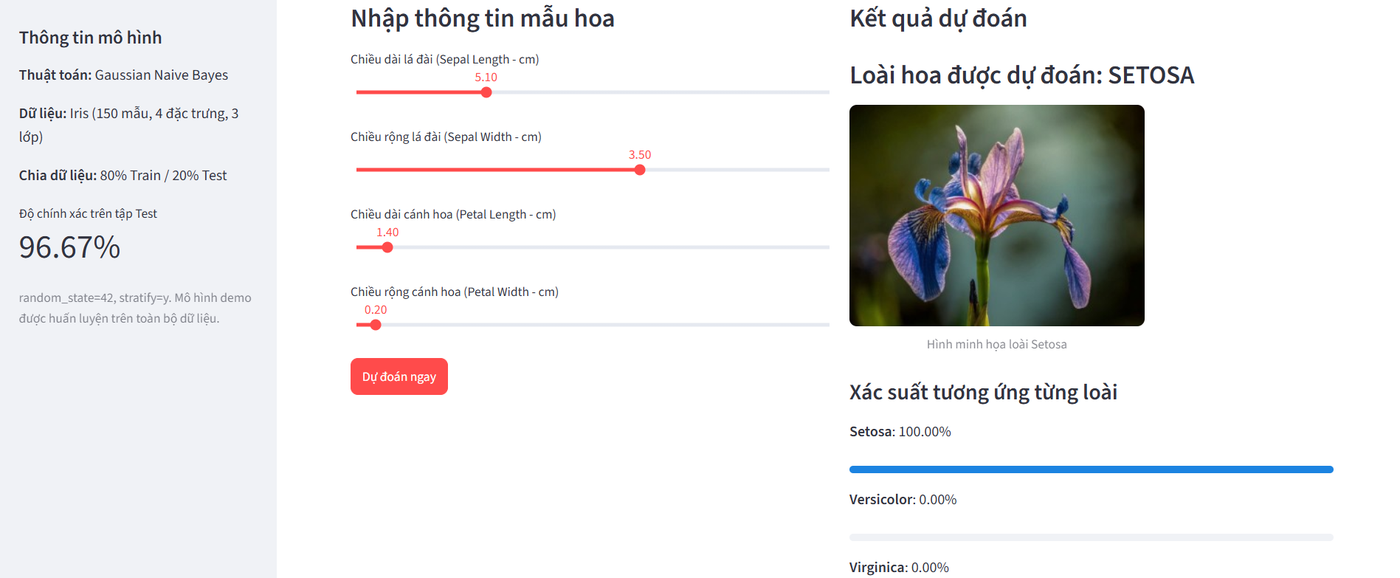

**Vị trí mẫu hoa trên biểu đồ phân bố (ngôi sao vàng là điểm vừa nhập):**

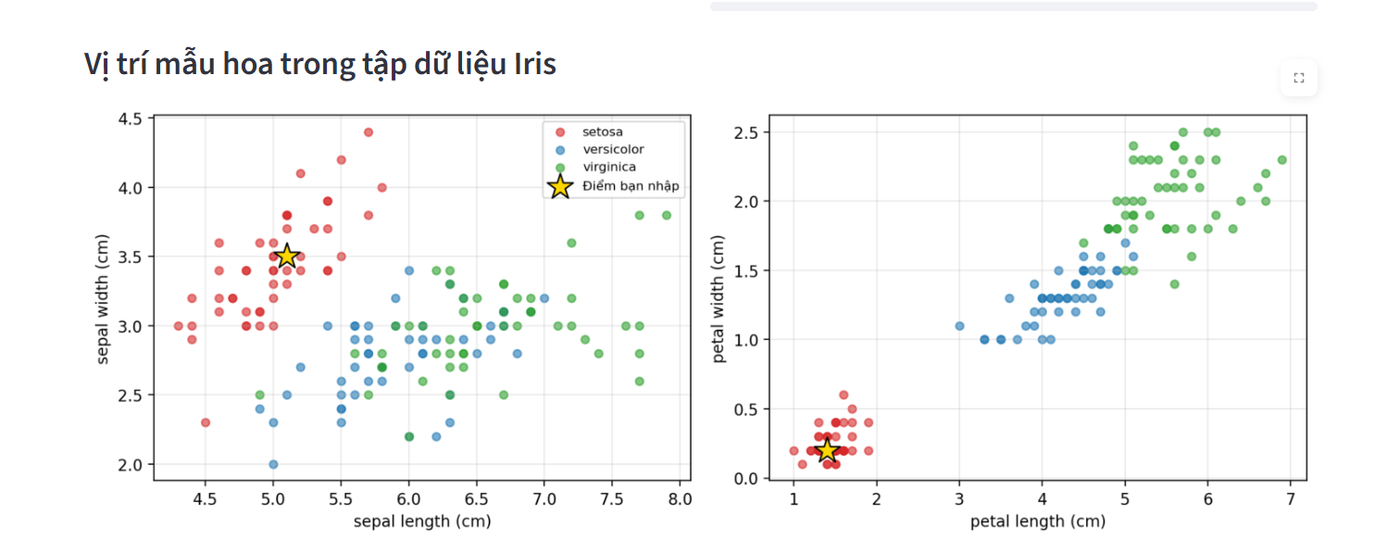

### Ca 2: (6.0, 2.9, 4.5, 1.5) → VERSICOLOR (98.65%)

**Giao diện và kết quả dự đoán:**

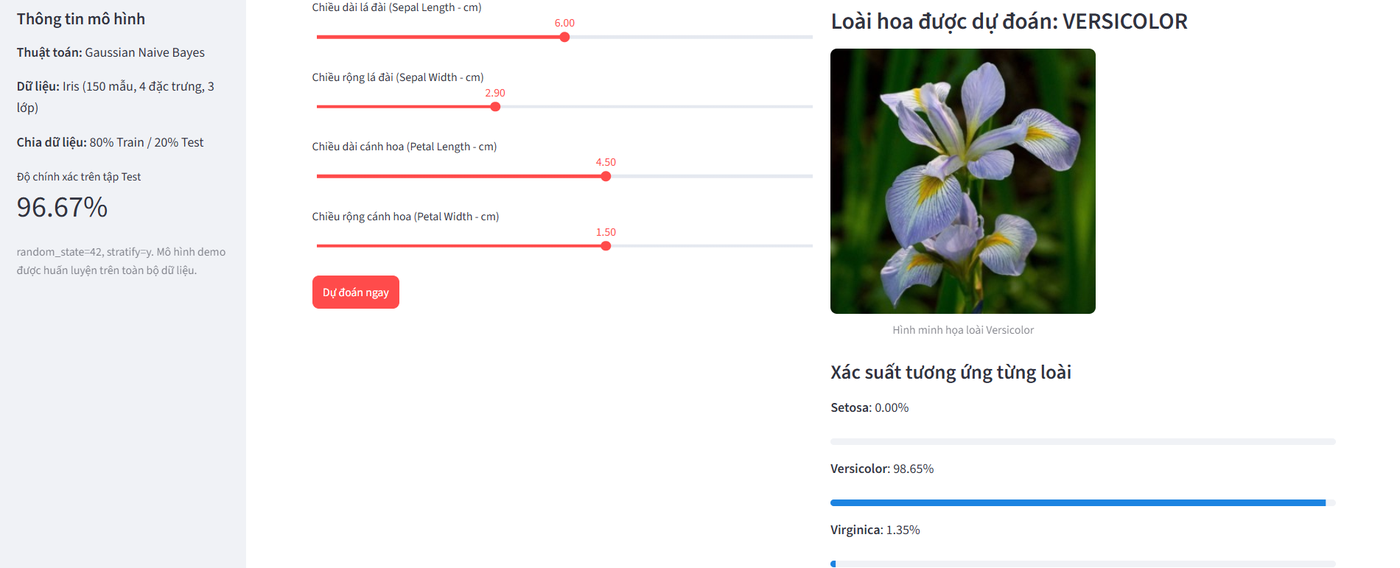

**Vị trí mẫu hoa trên biểu đồ phân bố (ngôi sao vàng là điểm vừa nhập):**

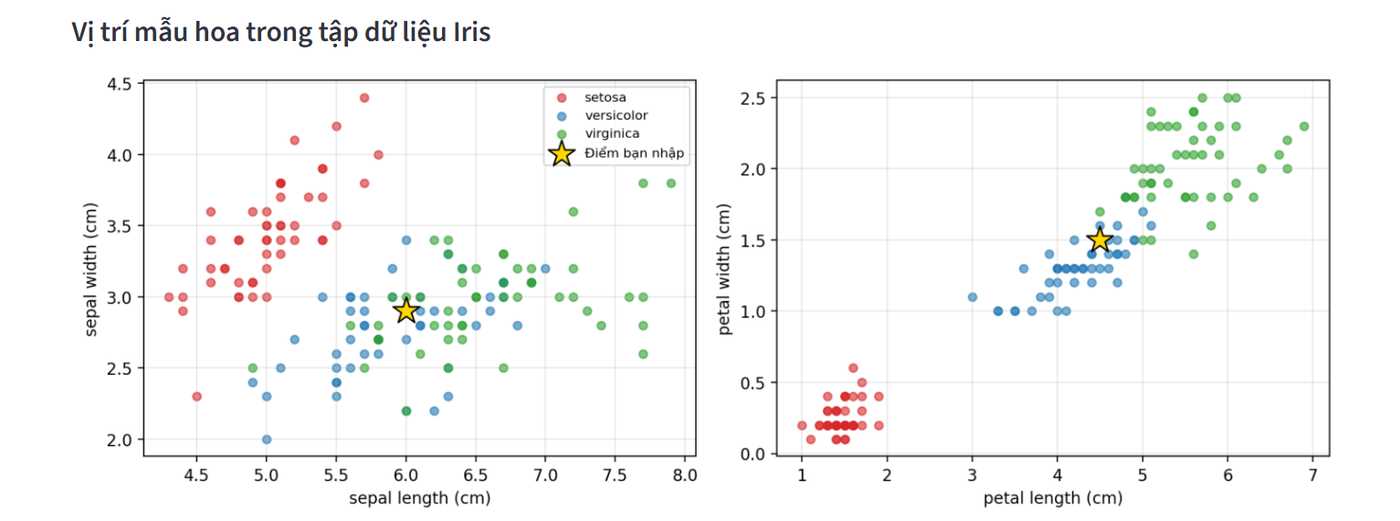

### Ca 3: (6.5, 3.0, 5.8, 2.2) → VIRGINICA (100%)

**Giao diện và kết quả dự đoán:**

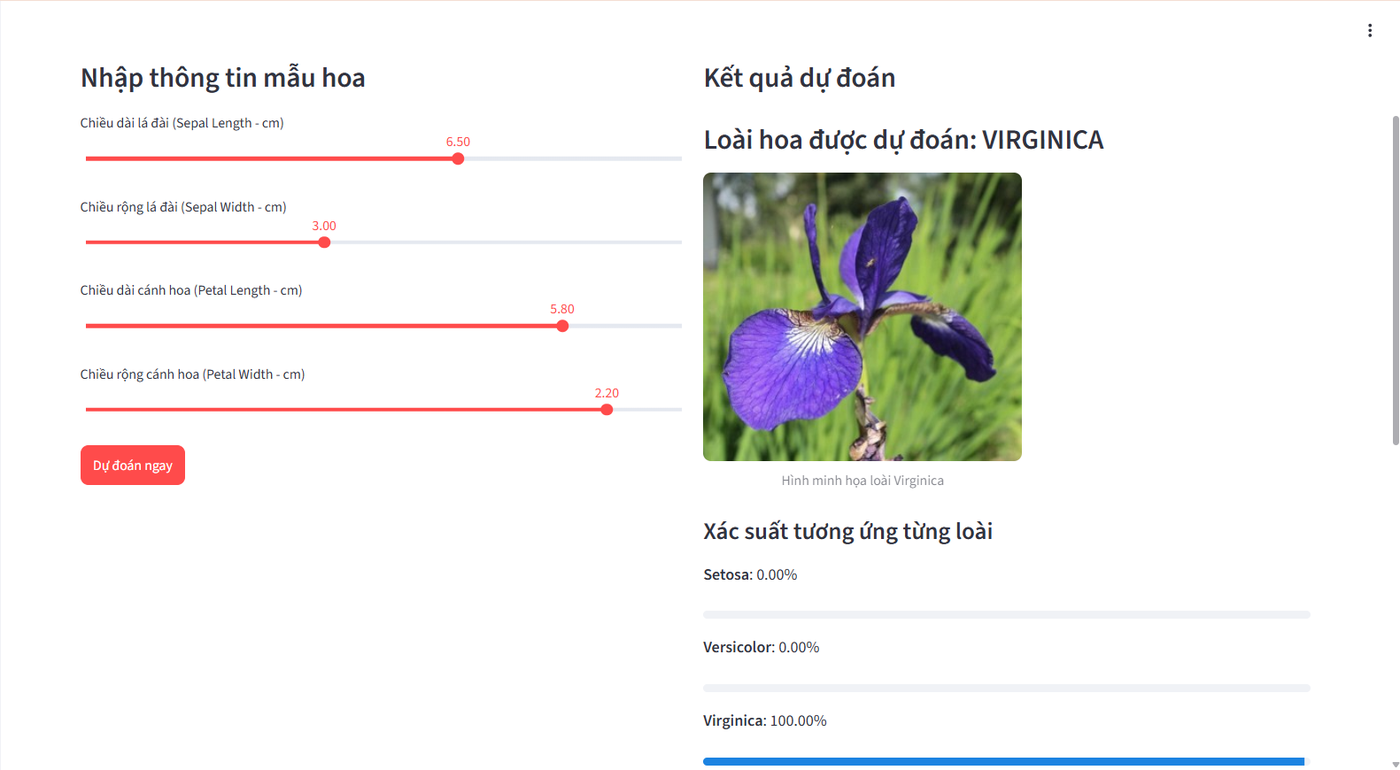

**Vị trí mẫu hoa trên biểu đồ phân bố (ngôi sao vàng là điểm vừa nhập):**

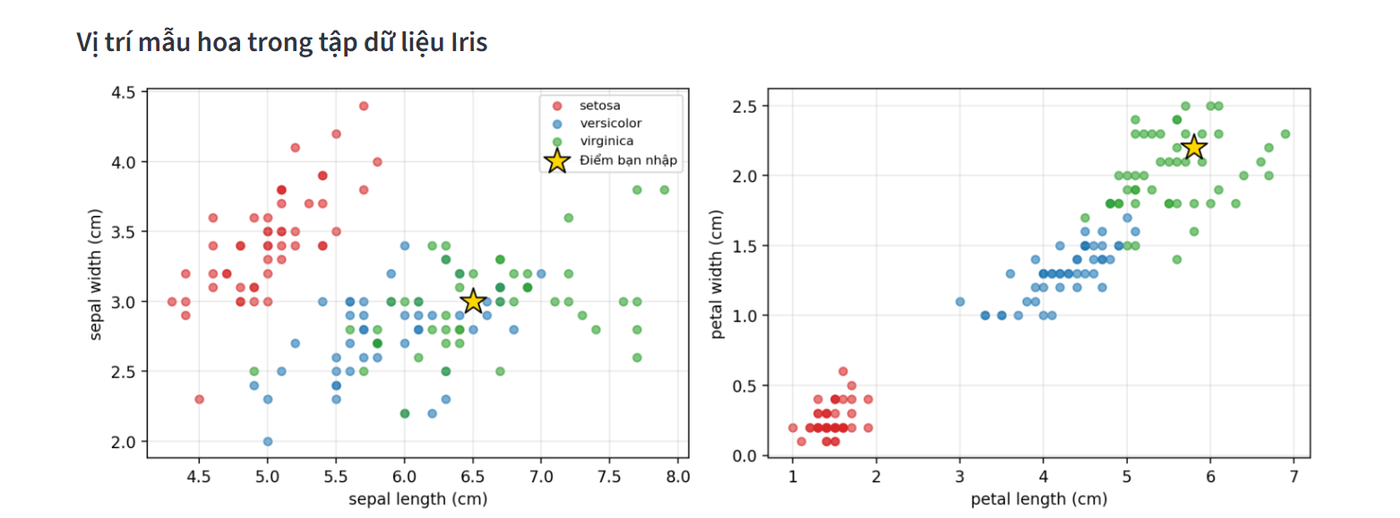

### Ca 4: (6.0, 2.7, 5.0, 1.7) → VIRGINICA 59.01% / VERSICOLOR 40.99%

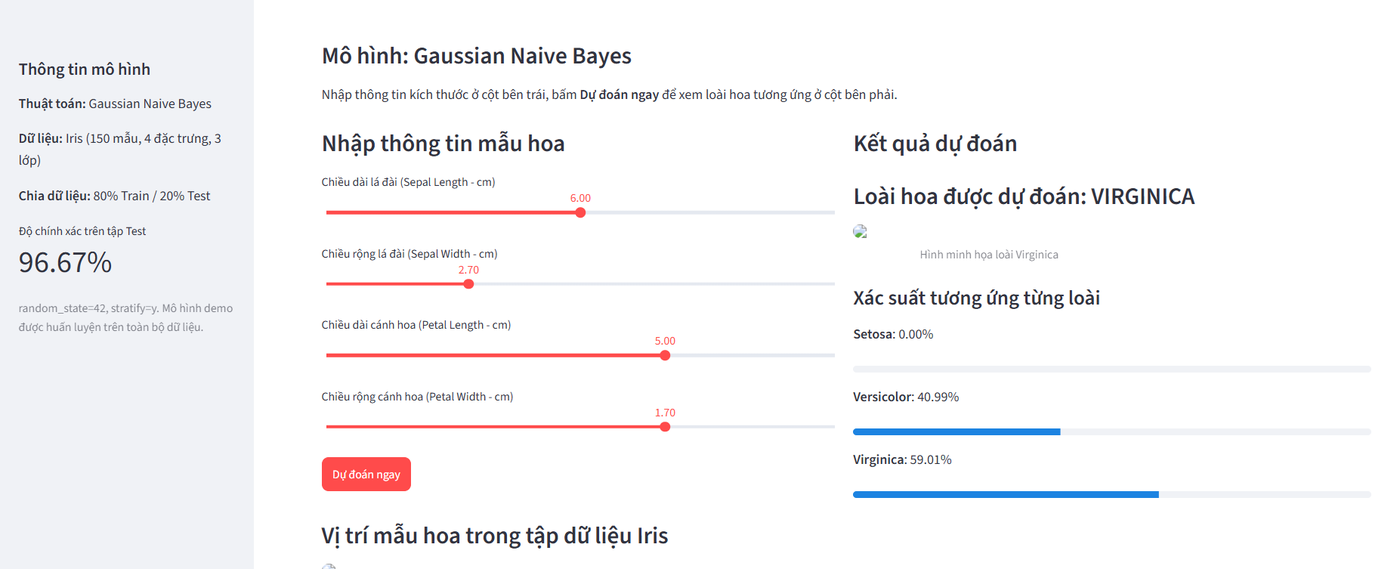

**Nhận xét trường hợp 4:** mẫu (6.0, 2.7, 5.0, 1.7) có chiều dài và chiều rộng cánh hoa nằm ở vùng giao nhau giữa Versicolor và Virginica trên biểu đồ phân bố. Vì vậy mô hình chia xác suất khá sát nhau (Virginica 59.01% so với Versicolor 40.99%), chỉ nghiêng nhẹ về Virginica, còn Setosa gần như bằng 0 vì loài này tách biệt hẳn. Điều này cho thấy mô hình không chắc chắn với các mẫu nằm ở ranh giới; xác suất cho biết mức tin cậy, hữu ích hơn việc chỉ xem nhãn dự đoán. Ngoài ra Gaussian Naive Bayes giả định các đặc trưng độc lập, trong khi thực tế chiều dài và chiều rộng cánh hoa tương quan mạnh, nên xác suất có thể chưa được hiệu chỉnh tốt.

## Chức năng nâng cao (bonus)

**1. Sidebar thông tin mô hình và độ chính xác 96.67% trên tập Test** (80/20, random_state=42, stratify=y), kèm biểu đồ phân bố có đánh dấu điểm người dùng nhập:

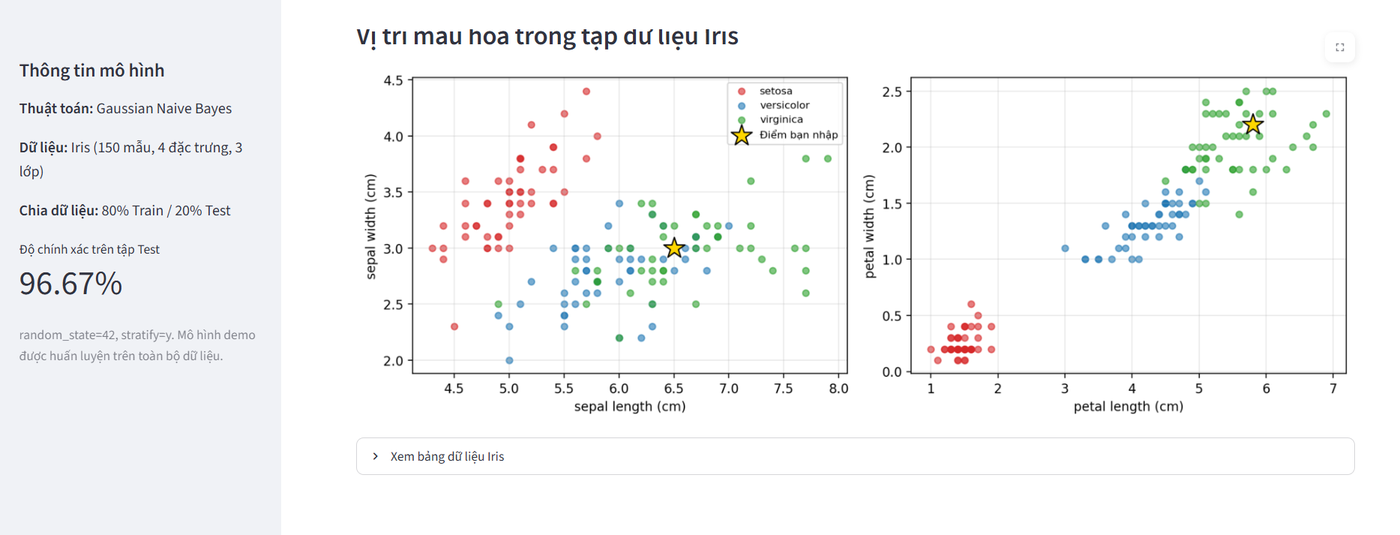

**2. Xem bảng dữ liệu Iris bằng `st.dataframe` trong expander:**

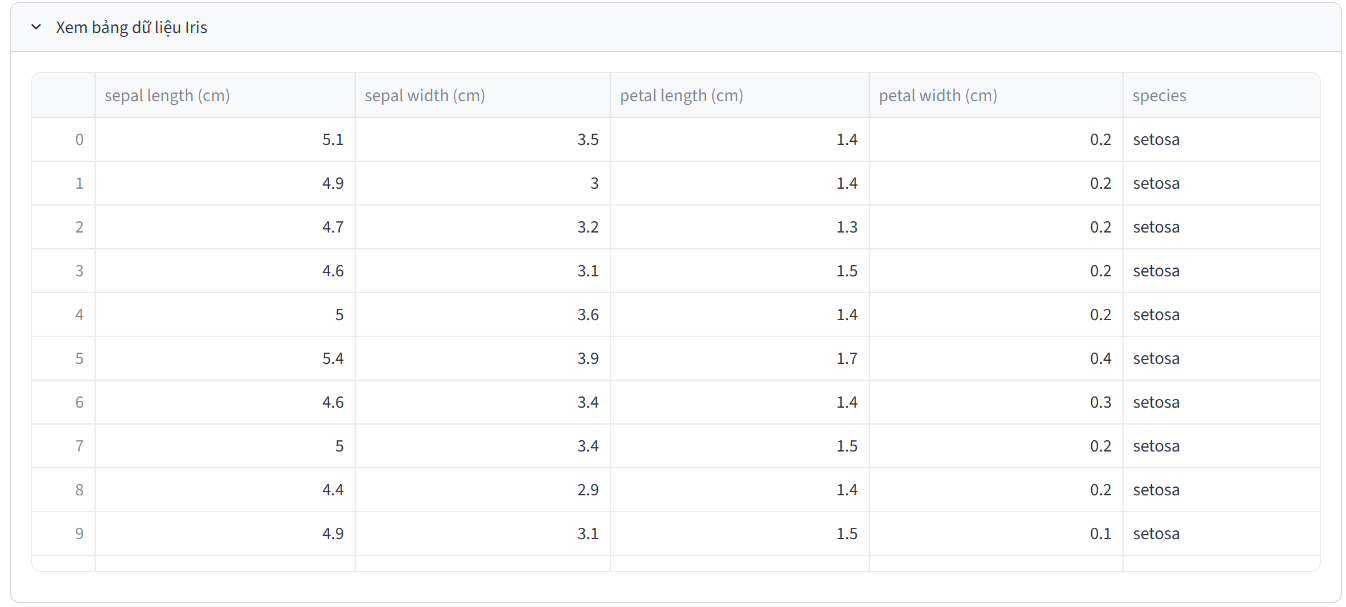

**3. Biểu đồ phân bố (scatter plot) đánh dấu điểm người dùng vừa nhập:** xem ảnh scatter ở từng ca phía trên.

**4. Xử lý lỗi khi thiếu file ảnh:** hàm `show_species_image` kiểm tra `os.path.exists`, nếu không thấy file thì hiện `st.warning` thay vì làm ứng dụng dừng.

## So sánh Gradio và Streamlit

| Chức năng | Gradio | Streamlit |
|---|---|---|
| Cấu hình trang | `gr.Blocks(title=...)` | `st.set_page_config(page_title=..., layout="wide")` |
| Tiêu đề / Markdown | `gr.Markdown(...)` | `st.title`, `st.markdown` |
| Chia cột | `gr.Row()` + `gr.Column()` | `st.columns(2)` |
| Thanh trượt | `gr.Slider(...)` | `st.slider(...)` |
| Nút bấm | `gr.Button` + `.click(...)` | `if st.button(...):` |
| Hiển thị ảnh | `gr.Image` | `st.image` |
| Hiển thị xác suất | `gr.Label` | `st.progress`, `st.bar_chart` |
| Chạy ứng dụng | `demo.launch()` | `streamlit run app.py` |

Điểm khác chính: Gradio theo mô hình hàm + sự kiện (inputs → fn → outputs), còn Streamlit chạy lại toàn bộ file mỗi lần người dùng tương tác với widget, nên phải dùng `@st.cache_resource` để mô hình chỉ huấn luyện một lần.